# Deskripsi Liblary Yang Di Gunakan

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Memanggil Dataset dan Deskripsi

In [5]:
df = pd.read_csv("toyota.csv")
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,GT86,2016,16000,Manual,24089,Petrol,265,36.2,2.0
1,GT86,2017,15995,Manual,18615,Petrol,145,36.2,2.0
2,GT86,2015,13998,Manual,27469,Petrol,265,36.2,2.0
3,GT86,2017,18998,Manual,14736,Petrol,150,36.2,2.0
4,GT86,2017,17498,Manual,36284,Petrol,145,36.2,2.0


# Melihat Jumlah Baris

In [6]:
df.shape

(6738, 9)

# Info dataset

In [7]:
df.info()
df.isnull().sum()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 6738 entries, 0 to 6737
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         6738 non-null   str    
 1   year          6738 non-null   int64  
 2   price         6738 non-null   int64  
 3   transmission  6738 non-null   str    
 4   mileage       6738 non-null   int64  
 5   fuelType      6738 non-null   str    
 6   tax           6738 non-null   int64  
 7   mpg           6738 non-null   float64
 8   engineSize    6738 non-null   float64
dtypes: float64(2), int64(4), str(3)
memory usage: 473.9 KB


,year,price,mileage,tax,mpg,engineSize
count,6738.000000,6738.000000,6738.000000,6738.000000,6738.000000,6738.000000
mean,2016.748145,12522.391066,22857.413921,94.697240,63.042223,1.471297
std,2.204062,6345.017587,19125.464147,73.880776,15.836710,0.436159
min,1998.000000,850.000000,2.000000,0.000000,2.800000,0.000000
25%,2016.000000,8290.000000,9446.000000,0.000000,55.400000,1.000000
50%,2017.000000,10795.000000,18513.000000,135.000000,62.800000,1.500000
75%,2018.000000,14995.000000,31063.750000,145.000000,69.000000,1.800000
max,2020.000000,59995.000000,174419.000000,565.000000,235.000000,4.500000


<Axes: >

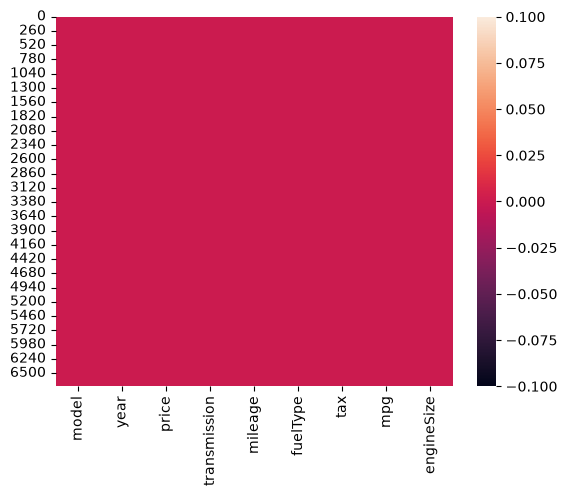

In [8]:
sns.heatmap(df.isnull())

# Visualisasi Data

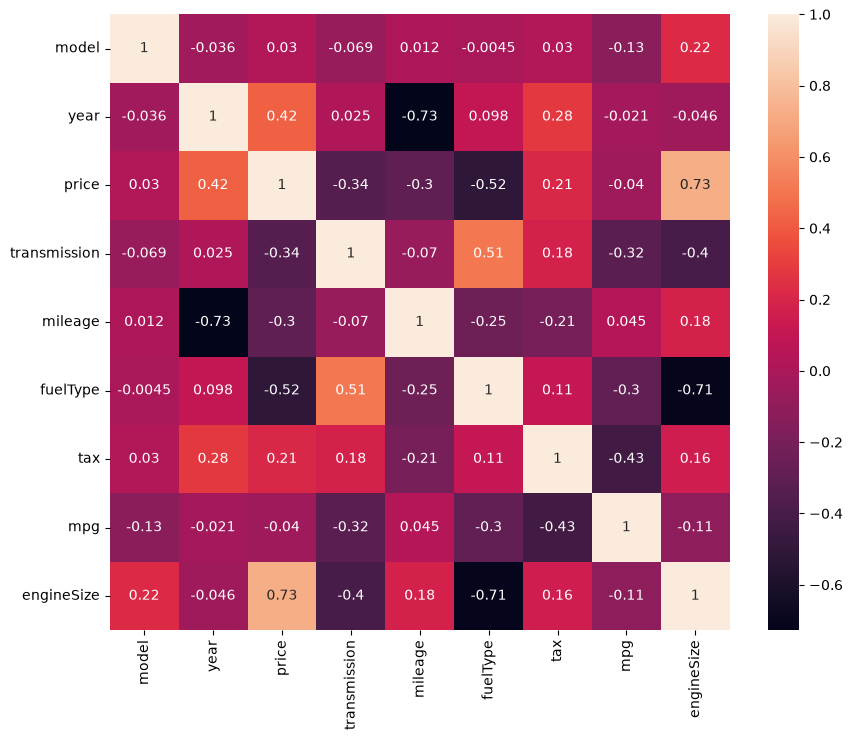

In [9]:
df["model"] = df["model"].str.strip()

df_num = df.copy()
for col in df_num.select_dtypes(exclude="number").columns:
    df_num[col] = df_num[col].astype("category").cat.codes

plt.figure(figsize=(10, 8))
sns.heatmap(df_num.corr(), annot=True)
plt.show()

# Jumlah Mobil Berdasarkan Model

In [10]:
df["model"] = df["model"].str.strip()

models = df.groupby('model').count()[['tax']].sort_values(by='tax', ascending=True).reset_index()
models = models.rename(columns={'tax': 'Jumlah'})
models

,model,Jumlah
0,Verso-S,3
1,Urban Cruiser,4
2,IQ,8
3,Camry,11
4,Supra,12
5,PROACE VERSO,15
6,Land Cruiser,51
7,GT86,73
8,Hilux,86
9,Verso,114


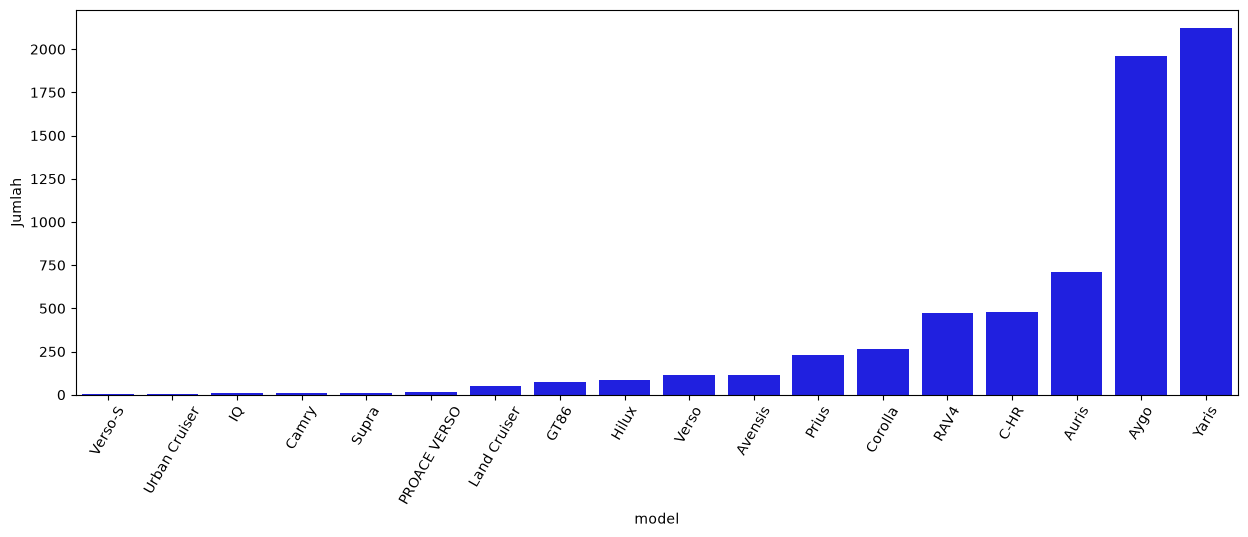

In [11]:
fig = plt.figure(figsize=(15, 5))
sns.barplot(x=models['model'], y=models['Jumlah'], color='blue')
plt.xticks(rotation=60)
plt.show()

# Ukuran Mesin

In [12]:
engine = df.groupby('engineSize').count()[['tax']].sort_values(by='tax').reset_index()
engine = engine.rename(columns={'tax': 'count'})
engine

,engineSize,count
0,4.5,1
1,4.2,1
2,0.0,6
3,3.0,35
4,2.8,36
5,1.4,40
6,2.2,58
7,2.4,70
8,1.6,169
9,2.5,249


<Axes: xlabel='engineSize', ylabel='count'>

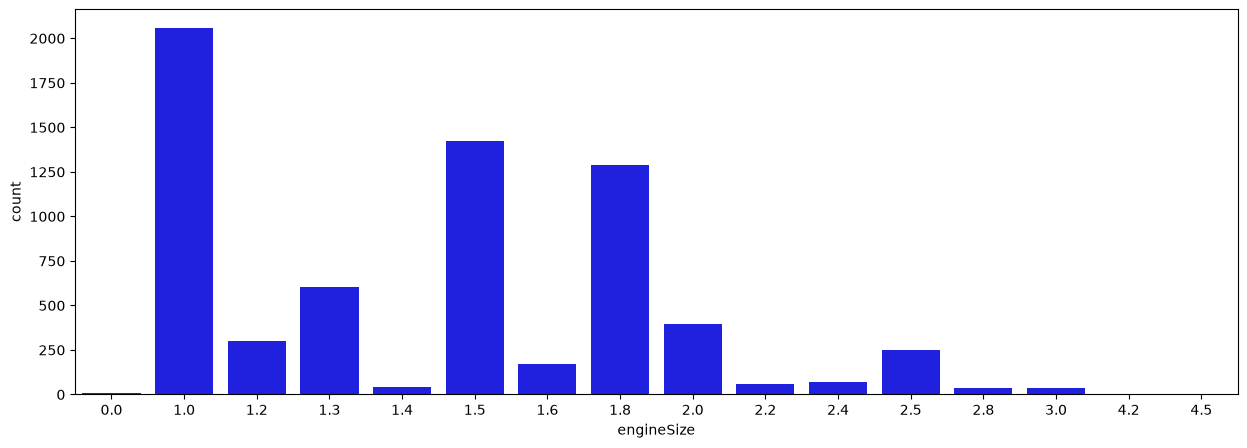

In [13]:
plt.figure(figsize=(15, 5))
sns.barplot(x=engine['engineSize'], y=engine['count'], color='blue')

# Distribusi Mileage

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10476\3423790836.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['mileage'])


<Axes: xlabel='mileage', ylabel='Density'>

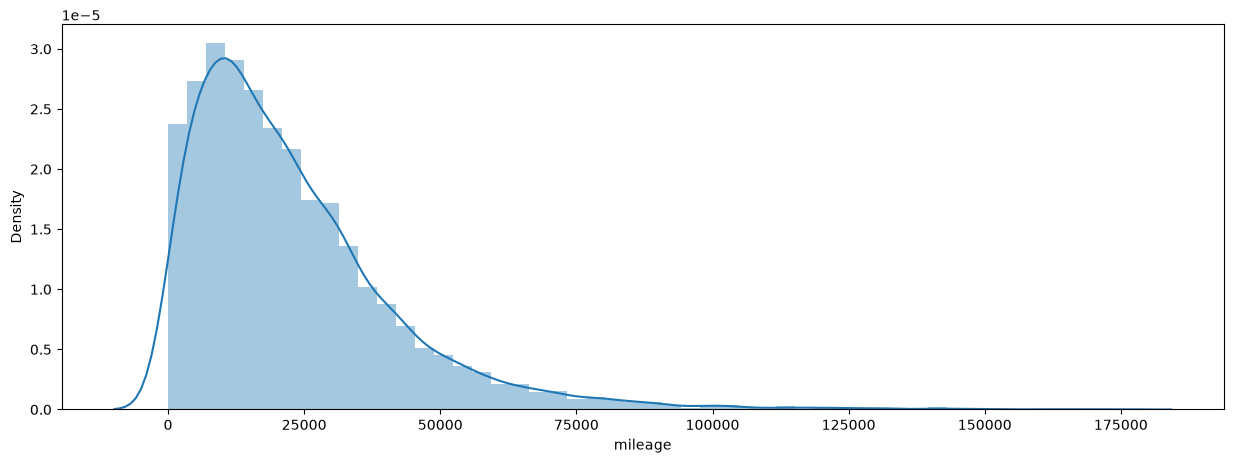

In [15]:
plt.figure(figsize=(15, 5))
sns.distplot(df['mileage'])

# Distribusi Harga Mobil

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10476\2973651063.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['price'])


<Axes: xlabel='price', ylabel='Density'>

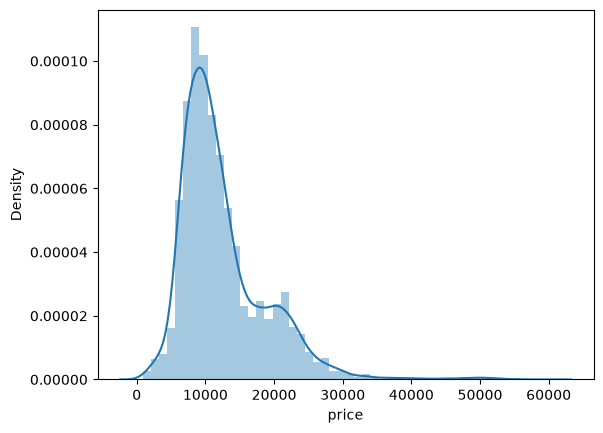

In [16]:
plt.Figure(figsize=(15, 5))
sns.distplot(df['price'])

# Seleksi Fitur

In [ ]:
features = ['year', 'mileage', 'tax', 'mpg', 'engineSize']
x = df[features]
y = df['price']
x.shape, y.shape

((6738, 5), (6738,))

# Split Data Training dan Testing

In [19]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y,random_state=70)
y_test.shape

(1685,)

# Membuat Model Regresi Linear

In [21]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train, y_train)
pred = lr.predict(x_test)

In [22]:
score = lr.score(x_test, y_test)
print("Akurasi Model Regresi Linear:", score)

Akurasi Model Regresi Linear: 0.7678983314475204


# Membuat Inputan Regresi Linear

In [24]:
input_data = np.array([[2019, 5000, 145, 30.2, 2]])

prediction = lr.predict(input_data)
print("Prediksi harga mobil:", prediction)

Prediksi harga mobil: [21208.50538579]


c:\Users\Lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# Save Model

In [28]:
import pickle
filename = 'estimasi_mobil.sav'
pickle.dump(lr, open(filename, 'wb'))